# 06 · General Linear Model (GLM) framework

**Idea:** correlation, t-test, ANOVA, regression and ANCOVA are all the same model, `y = Xβ + ε`, with different design matrices `X`.

**Important:** the competition target (`coverage_gap_score`) is hidden, so here we study *observable proxies* built only from the permitted data:

| proxy | meaning |
|---|---|
| `y_poi` | log of POIs per 100 buildings (a "how well-mapped are places" proxy) |
| `proxy_bldg_gap` | `1 - min(1, Overture buildings / USFS building count)`. Mimics the building component's *shape* (clipped at 0). The USFS count's provenance is still an open question, so this is for exploration only. |

This notebook also **builds the shared modelling table** `analysis_outputs/model_frame.parquet` used by notebooks 07-13.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)

## 0 · Build the modelling frame (one row per scored tract)

In [2]:
d = pd.read_parquet(OUT / "tract_analysis_table.parquet")
f = pd.DataFrame({"GEOID": d.GEOID, "region": d.region})
f["pop_density"] = d.pop_total / d.aland_km2.replace(0, np.nan)
f["log_pop_density"] = np.log1p(f.pop_density)
f["log_area_km2"] = np.log(d.aland_km2.clip(lower=0.01))
f["pct_urban"] = d.pct_urban
f["rural"] = d.rural.astype(int)
f["tribal"] = d.tribal.astype(int)
f["svi"] = d.svi_overall
f["cvi"] = d.cvi_overall
f["ruca"] = d.ruca_primary
f["water_share"] = d.water_share
f["share_msft"] = d.share_msft
f["share_osm"] = d.share_osm
f["bldg_per_hu"] = d.bldg_per_hu.replace(np.inf, np.nan)
f["log_road_density"] = np.log1p(d.road_km_per_km2)
f["hwy_share"] = d.hwy_share_of_road_km
f["wildfire_whp"] = d.usfs_WHP_mean
f["drought_summer"] = d.usdm_summer_dsci
f["heat_wbgt28"] = d.gehe_wbgt28_days_mean
f["heat_days_summer"] = d.epht_heat_days_summer
f["transit_any"] = (d.infra_n_transit > 0).astype(int)
f["bldg_n"], f["poi_n"], f["pop_total"] = d.bldg_n, d.poi_n, d.pop_total
f["fire_n"], f["ems_n"], f["school_n"] = d.poi_n_fire, d.poi_n_ems, d.poi_n_school
f["no_fire"] = (d.poi_n_fire == 0).astype(int)
f["y_poi"] = np.log(d.poi_per_100_bldg.replace([0, np.inf], np.nan))
r = d.bldg_n / d.usfs_BuildingCount_sum.replace(0, np.nan)
f["proxy_bldg_gap"] = 1 - r.clip(upper=1)
f.to_parquet(OUT / "model_frame.parquet")
print(f.shape); f[["y_poi", "proxy_bldg_gap", "no_fire", "fire_n", "poi_n"]].describe().T.round(3)

(9794, 31)


,count,mean,std,min,25%,50%,75%,max
y_poi,9792.0,2.172,1.092,-2.495,1.404,2.059,2.808,7.646
proxy_bldg_gap,9792.0,0.024,0.061,0.000,0.000,0.000,0.018,0.913
no_fire,9794.0,0.706,0.456,0.000,0.000,1.000,1.000,1.000
fire_n,9794.0,0.372,0.659,0.000,0.000,0.000,1.000,6.000
poi_n,9794.0,204.316,231.176,0.000,78.000,142.000,250.000,5236.000


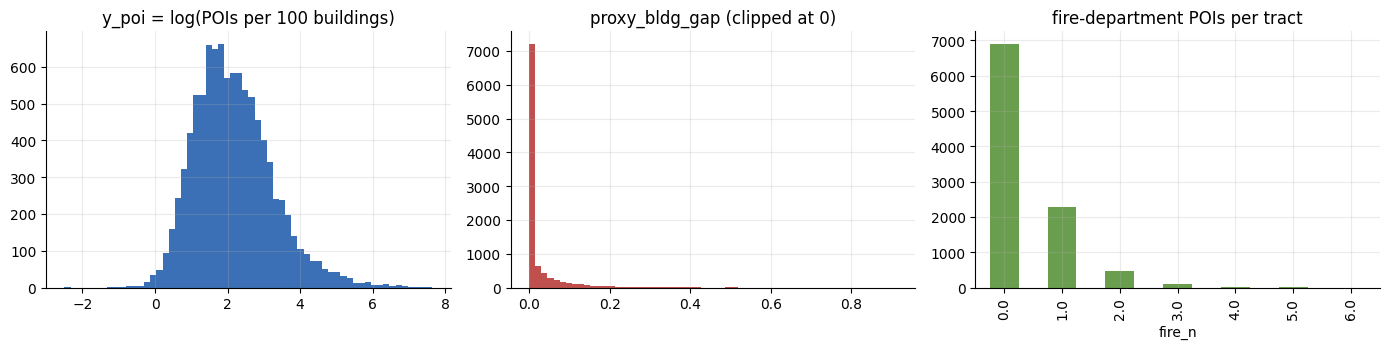

share of tracts with proxy_bldg_gap == 0: 0.641


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
f.y_poi.hist(bins=60, ax=ax[0], color="#3b6fb6"); ax[0].set_title("y_poi = log(POIs per 100 buildings)")
f.proxy_bldg_gap.hist(bins=60, ax=ax[1], color="#c0504d"); ax[1].set_title("proxy_bldg_gap (clipped at 0)")
f.fire_n.value_counts().sort_index().plot.bar(ax=ax[2], color="#6a9e4f"); ax[2].set_title("fire-department POIs per tract")
plt.tight_layout(); plt.show()
print("share of tracts with proxy_bldg_gap == 0:", round((f.proxy_bldg_gap == 0).mean(), 3))

**Comment:** `y_poi` is roughly bell-shaped, so ordinary least squares is reasonable. `proxy_bldg_gap` has a huge spike at exactly 0 (as the real target will), and fire POIs are small counts, which motivates the GLMs of notebook 08.

## 1 · Correlation *is* a simple regression
For standardised variables the regression slope equals Pearson's r, and the p-values are identical.

Pearson r = 0.3424 (p=1.88e-267)   |   standardised slope = 0.3424 (p=1.88e-267)


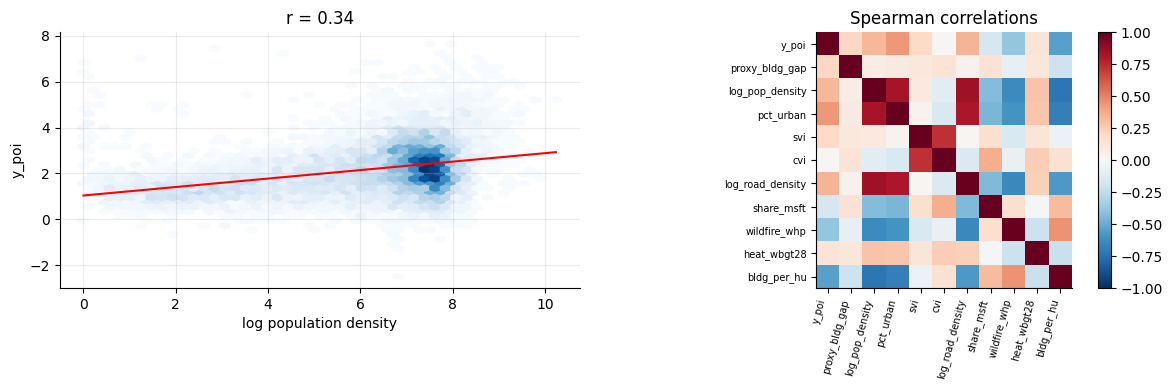

In [4]:
s = f[["y_poi", "log_pop_density"]].dropna()
r, p_r = stats.pearsonr(s.log_pop_density, s.y_poi)
z = (s - s.mean()) / s.std()
fit = smf.ols("y_poi ~ log_pop_density", z).fit()
print(f"Pearson r = {r:.4f} (p={p_r:.2e})   |   standardised slope = {fit.params['log_pop_density']:.4f} (p={fit.pvalues['log_pop_density']:.2e})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hexbin(s.log_pop_density, s.y_poi, gridsize=45, cmap="Blues", mincnt=1)
b = np.polyfit(s.log_pop_density, s.y_poi, 1); xs = np.linspace(s.log_pop_density.min(), s.log_pop_density.max(), 50)
ax[0].plot(xs, np.polyval(b, xs), "r"); ax[0].set(xlabel="log population density", ylabel="y_poi", title=f"r = {r:.2f}")
num = f[["y_poi", "proxy_bldg_gap", "log_pop_density", "pct_urban", "svi", "cvi", "log_road_density", "share_msft", "wildfire_whp", "heat_wbgt28", "bldg_per_hu"]].corr(method="spearman")
im = ax[1].imshow(num, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_xticks(range(len(num))); ax[1].set_xticklabels(num.columns, rotation=75, ha="right", fontsize=7)
ax[1].set_yticks(range(len(num))); ax[1].set_yticklabels(num.columns, fontsize=7); ax[1].grid(False); plt.colorbar(im, ax=ax[1]); ax[1].set_title("Spearman correlations")
plt.tight_layout(); plt.show()

**Comment:** r and the standardised slope match to every digit, so correlation is just regression. Denser (more urban) tracts have *more* POIs per building (r = +0.34): rural tracts have many outbuildings but few places, so a POI-per-building proxy is partly an urbanity signal.

## 2 · ANOVA *is* a regression on dummy variables
One-way ANOVA across regions gives the same F as the overall F of `y ~ C(region)`.

f_oneway: F=56.08, p=7.70e-47   |   OLS overall F=56.08, p=7.70e-47   |   R2=0.022
              sum_sq      df       F  PR(>F)
C(region)    261.604     4.0  56.076     0.0
Residual   11414.504  9787.0     NaN     NaN


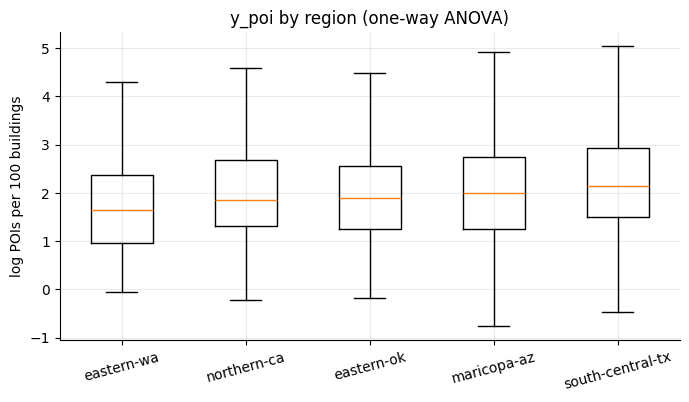

In [5]:
groups = [g.y_poi.dropna().values for _, g in f.groupby("region")]
F, p = stats.f_oneway(*groups)
m = smf.ols("y_poi ~ C(region)", f).fit()
print(f"f_oneway: F={F:.2f}, p={p:.2e}   |   OLS overall F={m.fvalue:.2f}, p={m.f_pvalue:.2e}   |   R2={m.rsquared:.3f}")
print(sm.stats.anova_lm(m, typ=2).round(3))
fig, ax = plt.subplots(figsize=(8, 4))
order = f.groupby("region").y_poi.median().sort_values().index
ax.boxplot([f.loc[f.region == r_, "y_poi"].dropna() for r_ in order], labels=order, showfliers=False)
ax.set_title("y_poi by region (one-way ANOVA)"); ax.set_ylabel("log POIs per 100 buildings"); plt.xticks(rotation=15); plt.show()

**Comment:** identical F in both routes. Region explains only about 2% of the variance (R2 = 0.022), so most variation is *within* regions.

## 3 · Multiple regression
Which tract characteristics go with POI density? Coefficients are on standardised predictors so they are comparable.

n=9706  R2=0.207  adj R2=0.206
cvi                -0.164
rural              -0.147
share_msft         -0.063
heat_wbgt28        -0.023
log_pop_density    -0.021
wildfire_whp        0.012
tribal              0.033
log_road_density    0.264
svi                 0.298


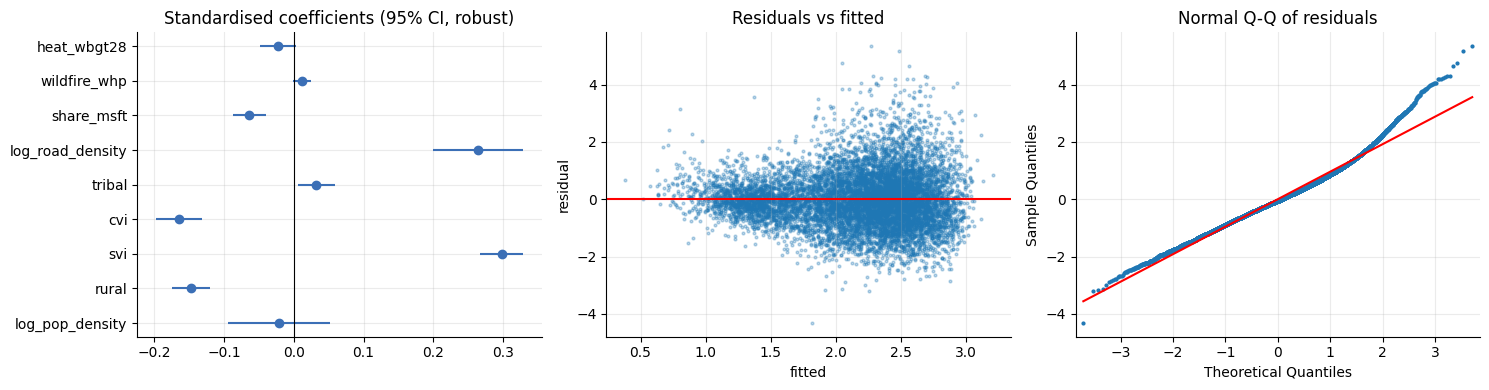

In [6]:
cols = ["log_pop_density", "rural", "svi", "cvi", "tribal", "log_road_density", "share_msft", "wildfire_whp", "heat_wbgt28"]
s = f[["y_poi", "region"] + cols].dropna().copy()
s[cols] = (s[cols] - s[cols].mean()) / s[cols].std()
m = smf.ols("y_poi ~ " + " + ".join(cols) + " + C(region)", s).fit(cov_type="HC3")
print(f"n={int(m.nobs)}  R2={m.rsquared:.3f}  adj R2={m.rsquared_adj:.3f}")
print(m.params[cols].round(3).sort_values().to_string())
ci = m.conf_int().loc[cols]; co = m.params[cols]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].errorbar(co, range(len(cols)), xerr=[co - ci[0], ci[1] - co], fmt="o", color="#3b6fb6"); ax[0].axvline(0, color="k", lw=.8)
ax[0].set_yticks(range(len(cols))); ax[0].set_yticklabels(cols); ax[0].set_title("Standardised coefficients (95% CI, robust)")
ax[1].scatter(m.fittedvalues, m.resid, s=4, alpha=.3); ax[1].axhline(0, color="r"); ax[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(m.resid, line="s", ax=ax[2], markersize=2); ax[2].set_title("Normal Q-Q of residuals")
plt.tight_layout(); plt.show()

**Comment:** the covariates plus region explain about 21% of the variance. Read the coefficient plot for direction and size; the Q-Q plot shows tails heavier than normal, so we report robust (HC3) errors.

## 4 · ANCOVA: comparing groups after adjusting for a covariate
Do tribal tracts have fewer POIs per building *after* accounting for how urban they are?

unadjusted tribal effect : -0.397  (p=8.1e-25)
ANCOVA-adjusted effect   : -0.066  (p=7.7e-02)
interaction (slopes differ?) p = 0.002


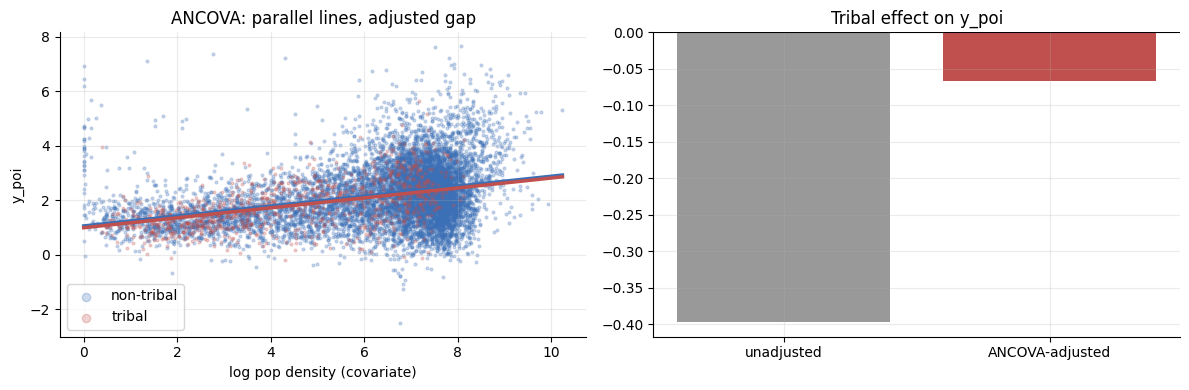

In [7]:
s = f[["y_poi", "tribal", "log_pop_density", "region"]].dropna()
raw = smf.ols("y_poi ~ tribal", s).fit()
anc = smf.ols("y_poi ~ tribal + log_pop_density", s).fit()
inter = smf.ols("y_poi ~ tribal * log_pop_density", s).fit()
print(f"unadjusted tribal effect : {raw.params['tribal']:+.3f}  (p={raw.pvalues['tribal']:.1e})")
print(f"ANCOVA-adjusted effect   : {anc.params['tribal']:+.3f}  (p={anc.pvalues['tribal']:.1e})")
print(f"interaction (slopes differ?) p = {inter.pvalues['tribal:log_pop_density']:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for t, c in ((0, "#3b6fb6"), (1, "#c0504d")):
    g = s[s.tribal == t]; ax[0].scatter(g.log_pop_density, g.y_poi, s=4, alpha=.25, color=c, label=["non-tribal", "tribal"][t])
    xs = np.linspace(s.log_pop_density.min(), s.log_pop_density.max(), 20)
    ax[0].plot(xs, anc.params["Intercept"] + anc.params["tribal"] * t + anc.params["log_pop_density"] * xs, color=c, lw=2.5)
ax[0].set(xlabel="log pop density (covariate)", ylabel="y_poi", title="ANCOVA: parallel lines, adjusted gap"); ax[0].legend(markerscale=3)
ax[1].bar(["unadjusted", "ANCOVA-adjusted"], [raw.params["tribal"], anc.params["tribal"]], color=["#999", "#c0504d"]); ax[1].axhline(0, color="k")
ax[1].set_title("Tribal effect on y_poi"); plt.tight_layout(); plt.show()

**Comment:** the raw gap (-0.40) shrinks to -0.07 and is no longer significant once density is held fixed. The covariate absorbs part of what looked like a group effect, which is the whole point of ANCOVA and a first hint at confounding (see notebooks 11-13).

## 5 · Case study: a GLM-based ML model for the clipped building gap
Predict `proxy_bldg_gap` from tract features with a regularised linear model. We compare against a region-mean baseline using a 5-fold CV, RMSE (the competition metric).

RMSE  constant mean : 0.0606
RMSE  region means  : 0.0603
RMSE  ridge (GLM)   : 0.0585


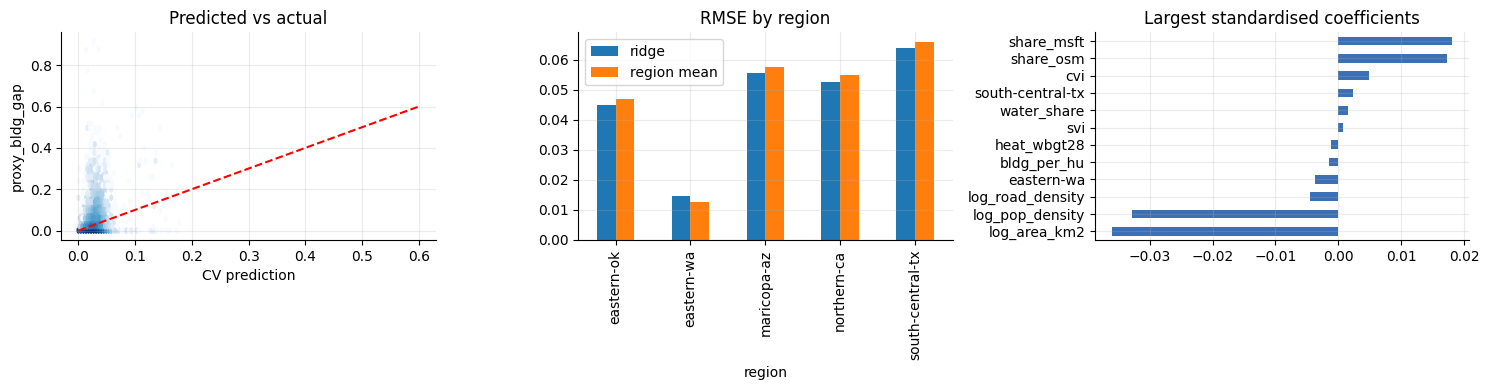

In [8]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
feat = ["log_pop_density", "rural", "svi", "cvi", "tribal", "log_road_density", "share_msft", "share_osm", "wildfire_whp", "heat_wbgt28", "bldg_per_hu", "log_area_km2", "water_share"]
s = f.dropna(subset=["proxy_bldg_gap"]).reset_index(drop=True)
X = pd.concat([s[feat], pd.get_dummies(s.region, dtype=float)], axis=1); y = s.proxy_bldg_gap
cv = KFold(5, shuffle=True, random_state=SEED)
base = cross_val_predict(LinearRegression(), pd.get_dummies(s.region, dtype=float), y, cv=cv)  # = region means
mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
pred = np.clip(cross_val_predict(mdl, X, y, cv=cv), 0, 1)
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(f"RMSE  constant mean : {rmse(y.mean(), y):.4f}\nRMSE  region means  : {rmse(base, y):.4f}\nRMSE  ridge (GLM)   : {rmse(pred, y):.4f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hexbin(pred, y, gridsize=40, cmap="Blues", mincnt=1, bins="log"); ax[0].plot([0, .6], [0, .6], "r--"); ax[0].set(xlabel="CV prediction", ylabel="proxy_bldg_gap", title="Predicted vs actual")
per = pd.DataFrame({"region": s.region, "e2": (pred - y) ** 2, "b2": (base - y) ** 2}).groupby("region").mean() ** .5
per.plot.bar(ax=ax[1]); ax[1].set_title("RMSE by region"); ax[1].legend(["ridge", "region mean"])
mdl.fit(X, y); co = pd.Series(mdl[-1].coef_, X.columns).sort_values(); co.iloc[np.r_[0:6, -6:0]].plot.barh(ax=ax[2], color="#3b6fb6"); ax[2].set_title("Largest standardised coefficients")
plt.tight_layout(); plt.show()

**Comment:** RMSE falls only from 0.0606 (constant) to 0.0585 (ridge), so tract features explain little of this zero-heavy outcome. Expect the real leaderboard to hinge on modelling the zero-spike and the region effect (see 08 and 13).